<a href="https://colab.research.google.com/github/rafi1624/Machine-Learning_18_Rafi-Abyantara/blob/main/JS10/JS10%20-%20Lab%204.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
	from pathlib import Path
	import numpy as np
	import matplotlib.pyplot as plt
	import cv2

	from skimage.feature import hog
	from sklearn.preprocessing import StandardScaler
	from sklearn.model_selection import train_test_split
	from sklearn.metrics import confusion_matrix, classification_report

	import tensorflow as tf
	from tensorflow.keras import layers, models

In [6]:
import zipfile
import os

# Ekstrak file zip yang diupload
zip_path = "/content/images (1).zip"

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall("/content/")
    print("Ekstraksi selesai! Silakan jalankan kembali sel di bawahnya.")
else:
    print(f"File {zip_path} tidak ditemukan. Pastikan file zip sudah diupload ke tab Files di sebelah kiri.")

Ekstraksi selesai! Silakan jalankan kembali sel di bawahnya.


In [8]:
	# Load images and labels from a directory structure
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    img_list = []
	    for folder in p.glob('*'):
	        label = folder.name
	        for file in folder.glob('*.jpg'):
	            img = cv2.imread(str(file))
	            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
	            img_list.append((img, label))
	    return img_list

	train_dir = "images/training/"
	test_dir  = "images/test/"

	train_img = load_dataset(train_dir)
	test_img  = load_dataset(test_dir)

In [9]:
	# Preprocess images: resize and encode labels
	def resize_image(img, size=(256,256)):
	    return cv2.resize(img, size)

	def label_encoder(label):
	    return 1 if label == 'day' else 0

	def preprocess(img_list):
	    X = []
	    y = []
	    for img, label in img_list:
	        img_std = resize_image(img)
	        X.append(img_std)
	        y.append(label_encoder(label))
	    return X, y

	X_train_img, y_train = preprocess(train_img)
	X_test_img,  y_test  = preprocess(test_img)

In [10]:
	# Extract HOG features
	def extract_hog(X_imgs):
	    feats = []
	    for img in X_imgs:
	        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
	        hog_feat = hog(gray,
	                       orientations=9,
	                       pixels_per_cell=(8,8),
	                       cells_per_block=(2,2),
	                       block_norm='L2-Hys',
	                       visualize=False,
	                       feature_vector=True)
	        feats.append(hog_feat)
	    return np.array(feats)

	X_train_feat = extract_hog(X_train_img)
	X_test_feat  = extract_hog(X_test_img)

In [12]:
	# Normalize features
	scaler = StandardScaler()
	X_train_scaled = scaler.fit_transform(X_train_feat)
	X_test_scaled  = scaler.transform(X_test_feat)

In [13]:
	X_train, X_val, y_train, y_val = train_test_split(
	    X_train_scaled, y_train,
	    test_size=0.2,
	    random_state=42
	)

	# Convert label ke numpy array
	y_train = np.array(y_train)
	y_val   = np.array(y_val)
	y_test  = np.array(y_test)

In [14]:
	input_dim = X_train.shape[1]

	model = models.Sequential([
	    layers.Input(shape=(input_dim,)),
	    layers.Dense(128, activation='relu'),
	    layers.Dense(64, activation='relu'),
	    layers.Dense(1, activation='sigmoid')
	])

	model.compile(
	    optimizer='adam',
	    loss='binary_crossentropy',
	    metrics=['accuracy']
	)

	model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
	history = model.fit(
	    X_train, y_train,
	    epochs=20,
	    batch_size=32,
	    validation_data=(X_val, y_val)
	)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 124ms/step - accuracy: 0.8073 - loss: 0.3689 - val_accuracy: 0.9792 - val_loss: 0.2723
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 72ms/step - accuracy: 0.9948 - loss: 0.0082 - val_accuracy: 0.9583 - val_loss: 0.4129
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - accuracy: 1.0000 - loss: 0.0016 - val_accuracy: 0.9583 - val_loss: 0.5524
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step - accuracy: 1.0000 - loss: 1.6998e-05 - val_accuracy: 0.9583 - val_loss: 0.6361
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step - accuracy: 1.0000 - loss: 1.6453e-05 - val_accuracy: 0.9583 - val_loss: 0.6814
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 1.0000 - loss: 8.3542e-06 - val_accuracy: 0.9583 - val_loss: 0.7070
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 1.0000 - loss: 6.0724e-06 - val_accuracy: 0.9583 - val_loss: 0.7209
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step - accuracy: 1.0000 - loss: 4.6279e-06 - val_accuracy: 0.958

In [16]:
	test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
	print("Akurasi Test:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.8813 - loss: 0.8679
Akurasi Test: 0.8812500238418579


In [17]:
	y_pred_prob = model.predict(X_test_scaled)
	y_pred = (y_pred_prob > 0.5).astype(int)

	print(classification_report(y_test, y_pred))
	print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step
              precision    recall  f1-score   support

           0       0.93      0.82      0.87        80
           1       0.84      0.94      0.89        80

    accuracy                           0.88       160
   macro avg       0.89      0.88      0.88       160
weighted avg       0.89      0.88      0.88       160

[[66 14]
 [ 5 75]]


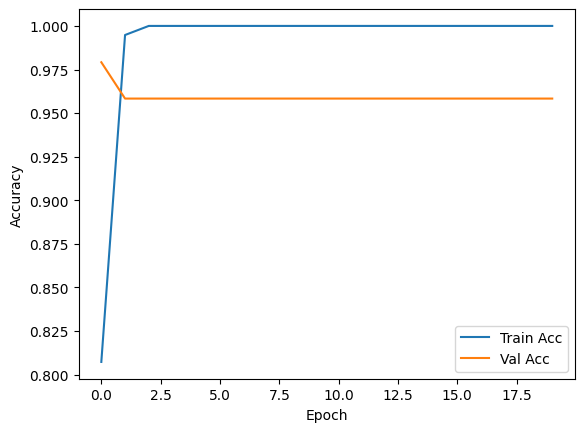

In [18]:
	plt.plot(history.history['accuracy'], label='Train Acc')
	plt.plot(history.history['val_accuracy'], label='Val Acc')
	plt.xlabel('Epoch')
	plt.ylabel('Accuracy')
	plt.legend()
	plt.show()

In [19]:
model.save('day_night_classifier_model.h5')